# 05 · Competitividad entre Tipos de Vendedor y Posicionamiento de Marcas (Objetivos 2 y 3)

**DS3021 Análisis Computacional de Datos · Proyecto Final, Parte II**

**Objetivo específico 2.** *Contrastar la competitividad tarifaria entre tipos de vendedores: comparar las distribuciones de precios y la agresividad de ofertas de Falabella (y sus filiales) frente a los vendedores externos (sellers), estratificando por categoría de producto y nivel de gama, para verificar si los terceros representan una alternativa más económica.*

**Objetivo específico 3.** *Examinar el posicionamiento y la dispersión de costos por marca: determinar la mediana y la dispersión de precios entre las principales marcas de cada categoría, contrastando la rigidez de las gamas altas frente a la volatilidad de las marcas con presencia en cada segmento de precio.*

Este notebook trabaja sobre el dataset procesado `data/processed/falabella_processed.csv` (1,037 registros y 16 variables, 0 % de valores nulos), generado por `pipeline/processing_data.py`. Las tablas de resultados se exportan a `data/analysis/` y los gráficos a `data/analysis/figures/` y `docs/img/` (prefijos `ana_05` a `ana_10`), siguiendo la convención del notebook 04.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)

CATS = ["laptops", "phones", "tvs"]
TIERS = ["low", "mid", "high"]
SELLER_TYPES = ["FALABELLA_DIRECT", "MARKETPLACE_SELLER"]
PAL_SELLER = {"FALABELLA_DIRECT": "#2a78d6", "MARKETPLACE_SELLER": "#eb6834"}
ALPHA = 0.05

FIG_DOCS = ROOT / "docs" / "img"
FIG_ANA = ROOT / "data" / "analysis" / "figures"
ANA_DIR = ROOT / "data" / "analysis"
FIG_DOCS.mkdir(parents=True, exist_ok=True)
FIG_ANA.mkdir(parents=True, exist_ok=True)


def say(text):
    display(Markdown(text))


def savefig(name):
    plt.savefig(FIG_DOCS / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.savefig(FIG_ANA / f"{name}.png", dpi=160, bbox_inches="tight")


df = pd.read_csv(ROOT / "data" / "processed" / "falabella_processed.csv")
df["prices_category"] = pd.Categorical(df["prices_category"], categories=TIERS, ordered=True)
print(f"Dataset procesado: {df.shape[0]} filas x {df.shape[1]} columnas")
print(f"Valores nulos en todo el dataset: {int(df.isna().sum().sum())}")

Dataset procesado: 1037 filas x 16 columnas
Valores nulos en todo el dataset: 0


## 0. Decisiones metodológicas

Antes de comparar grupos se fijan cuatro criterios. Cada uno responde a una característica concreta del dataset y se pone a prueba en la sección 1.4 (análisis de robustez).

| # | Decisión | Justificación |
|---|---|---|
| 1 | En el Objetivo 2 se comparan solo **equipos nuevos** (`is_refurbished == 0`). | Todos los equipos reacondicionados del catálogo pertenecen a vendedores externos. Si se incluyen, los sellers parecerían más baratos solo porque venden equipos usados, no porque ofrezcan mejores precios por el mismo tipo de producto. |
| 2 | Se **mantienen** los precios marcados como atípicos (`is_price_outlier == 1`). | Son productos reales de gama alta (Fueron marcados en el preprocesamiento, más no fueron eliminados). Las pruebas usadas se basan en rangos y no se ven arrastradas por valores extremos. Se repite el análisis sin ellos como control. |
| 3 | Se excluye `GENERICO` de los rankings de marca (Objetivo 3). | No es una marca real: es la etiqueta que usa la tienda cuando el vendedor no declara marca (11 filas). |
| 4 | Las diferencias entre grupos se evalúan con la **prueba U de Mann-Whitney** (bilateral, α = 0.05) dentro de cada categoría × gama, con corrección de **Holm** por las 9 comparaciones simultáneas. Entre varias marcas se usa **Kruskal-Wallis**. | Los precios son asimétricos (cola larga a la derecha) y los grupos de Falabella son pequeños (10 a 28 productos por celda), por lo que no se puede suponer normalidad. Comparar dentro de cada gama controla el efecto de que un tipo de vendedor ofrezca productos más caros en general. La corrección de Holm evita "encontrar" diferencias por azar al hacer muchas pruebas. |

Como medida de tamaño del efecto se reporta la **correlación biserial de rangos** $r_{rb} = 2U_F/(n_F\,n_M) - 1$, que va de −1 a 1: un valor positivo indica que los productos de Falabella tienden a tener valores mayores que los de los sellers externos, y uno negativo, lo contrario.

In [2]:
df_nuevos = df[df["is_refurbished"] == 0].copy()

resumen_decisiones = pd.DataFrame({
    "conjunto": ["Dataset procesado completo", "Equipos nuevos (Objetivo 2)", "Reacondicionados excluidos",
                 "  ...de ellos en FALABELLA_DIRECT", "Precios atípicos (se mantienen)", "Filas GENERICO (excluidas en Obj. 3)"],
    "filas": [len(df), len(df_nuevos), int(df["is_refurbished"].sum()),
              int(df.loc[df["is_refurbished"] == 1, "seller_type"].eq("FALABELLA_DIRECT").sum()),
              int(df["is_price_outlier"].sum()), int(df["brand"].eq("GENERICO").sum())],
})
display(resumen_decisiones)


def holm(pvals):
    # Corrección de Holm-Bonferroni para comparaciones múltiples
    p = np.asarray(pvals, dtype=float)
    m = len(p)
    adj = np.empty(m)
    running = 0.0
    for rank, idx in enumerate(np.argsort(p)):
        running = max(running, (m - rank) * p[idx])
        adj[idx] = min(running, 1.0)
    return adj


def mann_whitney(a, b):
    # Devuelve U de Falabella, p-valor bilateral y correlación biserial de rangos
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r_rb = 2 * u / (len(a) * len(b)) - 1
    return u, p, r_rb


def comparar_vendedores(data, variable):
    filas = []
    for cat in CATS:
        for tier in TIERS:
            sub = data[(data["category"] == cat) & (data["prices_category"] == tier)]
            a = sub.loc[sub["seller_type"] == "FALABELLA_DIRECT", variable]
            b = sub.loc[sub["seller_type"] == "MARKETPLACE_SELLER", variable]
            u, p, r_rb = mann_whitney(a, b)
            filas.append({
                "category": cat, "prices_category": tier,
                "n_falabella": len(a), "n_marketplace": len(b),
                "mediana_falabella": round(a.median(), 2), "mediana_marketplace": round(b.median(), 2),
                "dif_medianas_F_menos_M": round(a.median() - b.median(), 2),
                "U": round(u, 1), "p_value": p, "r_rank_biserial": round(r_rb, 3),
            })
    out = pd.DataFrame(filas)
    out["p_holm"] = holm(out["p_value"])
    out["significativo_p005"] = out["p_value"] < ALPHA
    out["significativo_holm"] = out["p_holm"] < ALPHA
    out["p_value"] = out["p_value"].round(4)
    out["p_holm"] = out["p_holm"].round(4)
    return out

,conjunto,filas
0,Dataset procesado completo,1037
1,Equipos nuevos (Objetivo 2),944
2,Reacondicionados excluidos,93
3,...de ellos en FALABELLA_DIRECT,0
4,Precios atípicos (se mantienen),53
5,Filas GENERICO (excluidas en Obj. 3),11


# Objetivo 2 · Falabella (y filiales) frente a Vendedores Externos

## 1.1 Composición del catálogo y concentración de vendedores

Primero se describe **quién vende qué**: cuánto del catálogo publica directamente el grupo Falabella (FALABELLA, TOTTUS y SODIMAC) y cuánto los vendedores externos, y qué tan repartida está la oferta entre vendedores. La concentración se mide con la participación de los 5 vendedores con más publicaciones y con el índice de Herfindahl-Hirschman (HHI = suma de las participaciones al cuadrado × 10,000). Ambas medidas se calculan sobre **publicaciones**, no sobre ventas, porque el dataset no contiene unidades vendidas.

In [3]:
composicion = (
    df.groupby(["category", "seller_type"]).size().unstack(fill_value=0)
    .reindex(index=CATS, columns=SELLER_TYPES)
)
composicion["total"] = composicion.sum(axis=1)
composicion["pct_falabella_direct"] = (composicion["FALABELLA_DIRECT"] / composicion["total"] * 100).round(1)
grupo = (
    df[df["seller_type"] == "FALABELLA_DIRECT"].groupby(["category", "seller"]).size()
    .unstack(fill_value=0).reindex(CATS)
)
composicion = composicion.join(grupo).reset_index()
composicion["refurbished_marketplace"] = [
    int(df[(df["category"] == c) & (df["seller_type"] == "MARKETPLACE_SELLER")]["is_refurbished"].sum()) for c in CATS
]
display(composicion)

filas = []
for cat in CATS:
    conteo = df.loc[df["category"] == cat, "seller"].value_counts()
    share = conteo / conteo.sum()
    filas.append({
        "category": cat,
        "publicaciones": int(conteo.sum()),
        "vendedores_distintos": len(conteo),
        "vendedores_con_1_publicacion": int((conteo == 1).sum()),
        "vendedor_lider": conteo.index[0],
        "pct_lider": round(share.iloc[0] * 100, 1),
        "pct_top5": round(share.head(5).sum() * 100, 1),
        "hhi": int(round((share ** 2).sum() * 10000)),
    })
conteo_total = df["seller"].value_counts()
share_total = conteo_total / conteo_total.sum()
filas.append({
    "category": "TOTAL", "publicaciones": int(conteo_total.sum()), "vendedores_distintos": len(conteo_total),
    "vendedores_con_1_publicacion": int((conteo_total == 1).sum()), "vendedor_lider": conteo_total.index[0],
    "pct_lider": round(share_total.iloc[0] * 100, 1), "pct_top5": round(share_total.head(5).sum() * 100, 1),
    "hhi": int(round((share_total ** 2).sum() * 10000)),
})
concentracion = pd.DataFrame(filas)
display(concentracion)

mix_gamas = (
    pd.crosstab([df_nuevos["category"], df_nuevos["seller_type"]], df_nuevos["prices_category"], normalize="index")
    .mul(100).round(1).reindex(columns=TIERS)
)
print("Distribución por gama (%) de los equipos nuevos de cada tipo de vendedor:")
display(mix_gamas)

composicion.to_csv(ANA_DIR / "vendedores_composicion_por_categoria.csv", index=False, encoding="utf-8")
concentracion.to_csv(ANA_DIR / "vendedores_concentracion_por_categoria.csv", index=False, encoding="utf-8")
mix_gamas.reset_index().to_csv(ANA_DIR / "vendedores_mix_gamas_equipos_nuevos.csv", index=False, encoding="utf-8")

,category,FALABELLA_DIRECT,MARKETPLACE_SELLER,total,pct_falabella_direct,FALABELLA,SODIMAC,TOTTUS,refurbished_marketplace
0,laptops,39,394,433,9.0,33,0,6,17
1,phones,57,380,437,13.0,38,3,16,76
2,tvs,59,108,167,35.3,42,7,10,0


,category,publicaciones,vendedores_distintos,vendedores_con_1_publicacion,vendedor_lider,pct_lider,pct_top5,hhi
0,laptops,433,83,28,NORTICO PE,8.3,33.3,362
1,phones,437,100,26,FALABELLA,8.7,25.2,247
2,tvs,167,41,17,FALABELLA,25.1,47.9,882
3,TOTAL,1037,186,59,FALABELLA,10.9,24.0,240


Distribución por gama (%) de los equipos nuevos de cada tipo de vendedor:


prices_category               low   mid  high
category seller_type                         
laptops  FALABELLA_DIRECT    28.2  43.6  28.2
         MARKETPLACE_SELLER  34.2  31.3  34.5
phones   FALABELLA_DIRECT    17.5  36.8  45.6
         MARKETPLACE_SELLER  41.1  26.6  32.2
tvs      FALABELLA_DIRECT    25.4  27.1  47.5
         MARKETPLACE_SELLER  38.9  36.1  25.0

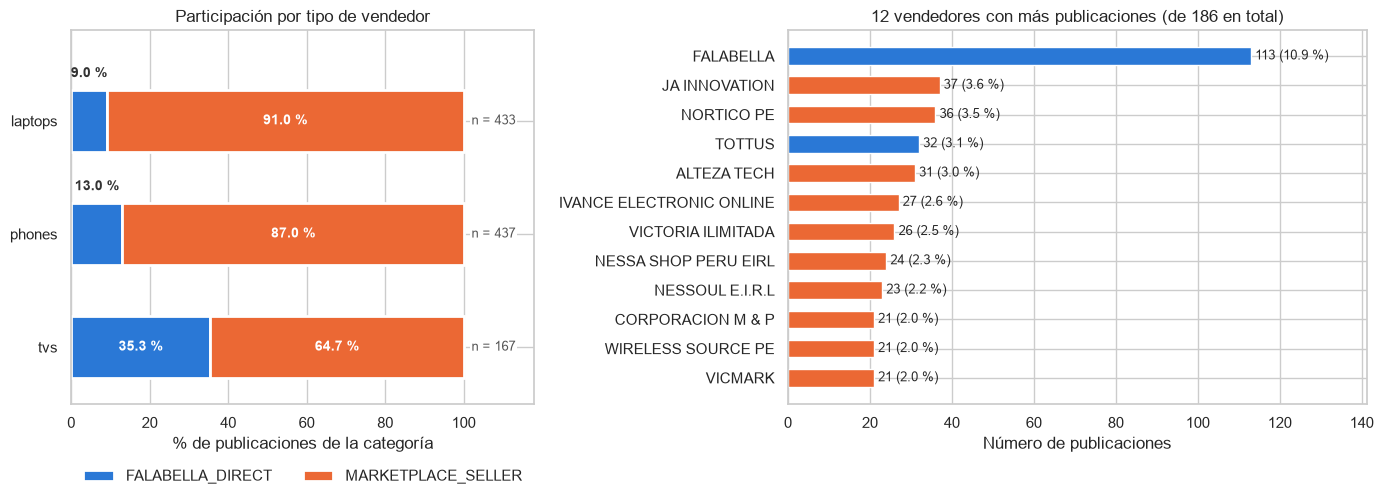

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.25]})

# Panel izquierdo: participación de cada tipo de vendedor por categoría (barras 100 % apiladas)
ax = axes[0]
pct = composicion.set_index("category")[SELLER_TYPES].div(composicion.set_index("category")["total"], axis=0) * 100
left = np.zeros(len(CATS))
for st in SELLER_TYPES:
    ax.barh(CATS, pct[st], left=left, color=PAL_SELLER[st], edgecolor="white", linewidth=2, label=st, height=0.55)
    for i, v in enumerate(pct[st]):
        if v >= 15:
            ax.text(left[i] + v / 2, i, f"{v:.1f} %", ha="center", va="center", color="white", fontsize=10, fontweight="bold")
        else:  # segmento angosto: etiqueta encima de la barra
            ax.text(left[i] + v / 2, i - 0.36, f"{v:.1f} %", ha="center", va="bottom", color="#333333", fontsize=10, fontweight="bold")
    left += pct[st].values
for i, cat in enumerate(CATS):
    ax.text(102, i, f"n = {int(composicion.loc[i, 'total'])}", va="center", fontsize=9, color="#555555",
            bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.set_xlim(0, 118)
ax.set_ylim(len(CATS) - 0.5, -0.8)
ax.set_xlabel("% de publicaciones de la categoría")
ax.set_title("Participación por tipo de vendedor")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)

# Panel derecho: los 12 vendedores con más publicaciones
ax = axes[1]
top = df["seller"].value_counts().head(12)
tipo = df.drop_duplicates("seller").set_index("seller")["seller_type"]
ax.barh(top.index, top.values, color=[PAL_SELLER[tipo[s]] for s in top.index], height=0.6)
for i, v in enumerate(top.values):
    ax.text(v + 1, i, f"{v} ({v / len(df) * 100:.1f} %)", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, top.max() * 1.25)
ax.set_xlabel("Número de publicaciones")
ax.set_title(f"12 vendedores con más publicaciones (de {df['seller'].nunique()} en total)")

plt.tight_layout()
savefig("ana_05_composicion_vendedores")
plt.show()

**Interpretación.**

- **El catálogo lo publican sobre todo terceros.** El 85.1 % de las publicaciones (882 de 1,037) son de vendedores externos. El grupo Falabella (FALABELLA, TOTTUS y SODIMAC) publica directamente solo el 9.0 % de las laptops y el 13.0 % de los celulares, pero el **35.3 % de los televisores**: es la única categoría donde la venta directa tiene un peso relevante.
- **La oferta está muy repartida.** Hay 186 vendedores distintos y 59 de ellos tienen una sola publicación. FALABELLA es el vendedor con más publicaciones, con apenas el 10.9 % del catálogo; los 5 primeros suman el 24.0 % (HHI = 240). Por categoría, los televisores son la más concentrada (los 5 primeros publican el 47.9 %, HHI = 882), mientras que celulares (HHI = 247) y laptops (HHI = 362) están muy atomizados. Estos índices miden publicaciones, no ventas, porque el dataset no contiene unidades vendidas.
- **Cada tipo de vendedor ofrece una mezcla de gamas distinta.** Entre los equipos nuevos, Falabella concentra su oferta en la gama alta (45.6 % de sus celulares y 47.5 % de sus televisores son `high`), mientras que los sellers externos tienen más peso en la gama baja (41.1 % de sus celulares y 38.9 % de sus televisores son `low`). En laptops, Falabella se concentra en la gama media (43.6 %).
- **Los 93 equipos reacondicionados del catálogo (76 celulares y 17 laptops) son todos de vendedores externos.**

Las dos últimas observaciones son las que obligan a comparar precios **dentro de cada gama y solo con equipos nuevos**: si no, se confundiría "qué vende cada uno" con "a qué precio lo vende".

## 1.2 ¿Son los vendedores externos una alternativa más económica? (precio internet)

Se compara `internet_price` (el precio que paga el comprador) entre `FALABELLA_DIRECT` y `MARKETPLACE_SELLER` **dentro de cada categoría y gama**, solo con equipos nuevos. Comparar dentro de la misma gama es clave: si se comparara la categoría completa, cualquier diferencia podría deberse simplemente a que un tipo de vendedor ofrece más productos caros que el otro (efecto de composición).

In [5]:
mw_precio = comparar_vendedores(df_nuevos, "internet_price")
display(mw_precio)

# Comparación agregada por categoría (sin estratificar por gama), para contrastar
filas = []
for cat in CATS:
    sub = df_nuevos[df_nuevos["category"] == cat]
    a = sub.loc[sub["seller_type"] == "FALABELLA_DIRECT", "internet_price"]
    b = sub.loc[sub["seller_type"] == "MARKETPLACE_SELLER", "internet_price"]
    u, p, r_rb = mann_whitney(a, b)
    filas.append({"category": cat, "n_falabella": len(a), "n_marketplace": len(b),
                  "mediana_falabella": a.median(), "mediana_marketplace": b.median(),
                  "p_value": round(p, 4), "r_rank_biserial": round(r_rb, 3)})
mw_precio_agregado = pd.DataFrame(filas)
print("Comparación SIN estratificar por gama (solo como contraste):")
display(mw_precio_agregado)

mw_precio.to_csv(ANA_DIR / "mannwhitney_precio_por_vendedor_gama.csv", index=False, encoding="utf-8")
mw_precio_agregado.to_csv(ANA_DIR / "mannwhitney_precio_por_vendedor_categoria.csv", index=False, encoding="utf-8")

,category,prices_category,n_falabella,n_marketplace,mediana_falabella,mediana_marketplace,dif_medianas_F_menos_M,U,p_value,r_rank_biserial,p_holm,significativo_p005,significativo_holm
0,laptops,low,11,129,2449.0,2599.0,-150.0,634.5,0.5635,-0.106,1.0000,False,False
1,laptops,mid,17,118,3899.0,3789.0,110.0,1237.5,0.1205,0.234,0.9638,False,False
2,laptops,high,11,130,6599.0,6624.0,-25.0,771.5,0.6667,0.079,1.0000,False,False
3,phones,low,10,125,534.0,499.0,35.0,756.5,0.2709,0.210,1.0000,False,False
4,phones,mid,21,81,1399.0,1399.0,0.0,862.5,0.9241,0.014,1.0000,False,False
5,phones,high,26,98,3849.0,3414.0,435.0,1517.5,0.1357,0.191,0.9638,False,False
6,tvs,low,15,42,1199.0,1074.0,125.0,350.5,0.5257,0.113,1.0000,False,False
7,tvs,mid,16,39,1799.0,1729.0,70.0,324.5,0.8235,0.040,1.0000,False,False
8,tvs,high,28,27,3699.0,2999.0,700.0,485.0,0.0728,0.283,0.6552,False,False


Comparación SIN estratificar por gama (solo como contraste):


,category,n_falabella,n_marketplace,mediana_falabella,mediana_marketplace,p_value,r_rank_biserial
0,laptops,39,377,3899.0,3789.0,0.7780,0.027
1,phones,57,304,1899.0,1152.0,0.0007,0.283
2,tvs,59,108,1999.0,1614.0,0.0022,0.287


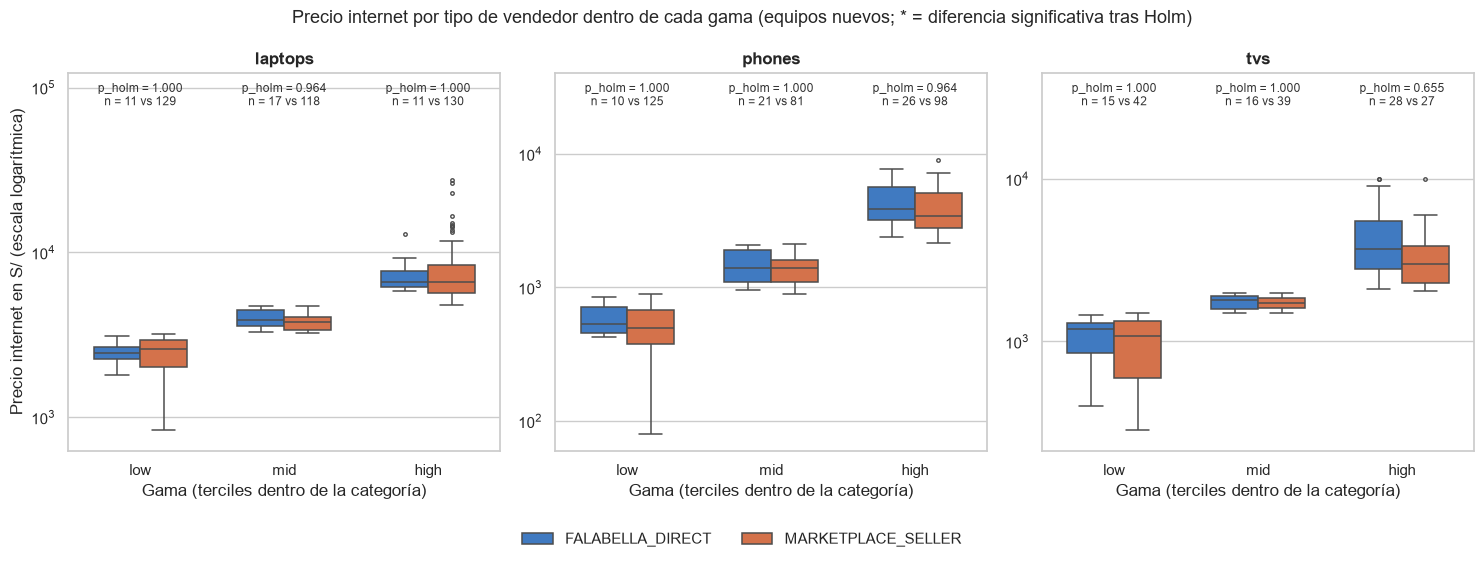

In [6]:
def boxplots_por_gama(data, variable, tabla_mw, ylabel, titulo, log=False):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
    for ax, cat in zip(axes, CATS):
        sub = data[data["category"] == cat]
        sns.boxplot(
            data=sub, x="prices_category", y=variable, hue="seller_type", order=TIERS, hue_order=SELLER_TYPES,
            palette=PAL_SELLER, width=0.65, fliersize=2.5, linewidth=1.1, ax=ax,
        )
        vmin, vmax = sub[variable].min(), sub[variable].max()
        if log:
            ax.set_yscale("log")
            ax.set_ylim(vmin * 0.75, vmax * 4.5)
        else:
            ax.set_ylim(min(0, vmin) - 3, vmax * 1.28)
        for i, tier in enumerate(TIERS):
            fila = tabla_mw[(tabla_mw["category"] == cat) & (tabla_mw["prices_category"] == tier)].iloc[0]
            marca = " *" if fila["significativo_holm"] else ""
            texto = f"p_holm = {fila['p_holm']:.3f}{marca}\nn = {fila['n_falabella']} vs {fila['n_marketplace']}"
            ax.text(i, 0.975, texto, ha="center", va="top", fontsize=8.5, color="#333333",
                    transform=ax.get_xaxis_transform())
        ax.set_title(cat, fontweight="bold")
        ax.set_xlabel("Gama (terciles dentro de la categoría)")
        ax.set_ylabel(ylabel if cat == "laptops" else "")
        ax.get_legend().remove()
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.04))
    fig.suptitle(titulo, fontsize=13)
    plt.tight_layout(rect=(0, 0.04, 1, 1))


boxplots_por_gama(
    df_nuevos, "internet_price", mw_precio, "Precio internet en S/ (escala logarítmica)",
    "Precio internet por tipo de vendedor dentro de cada gama (equipos nuevos; * = diferencia significativa tras Holm)",
    log=True,
)
savefig("ana_06_precio_vendedor_por_gama")
plt.show()

**Interpretación.**

- **Dentro de una misma categoría y gama, no hay diferencias de precio significativas entre Falabella y los sellers externos.** Ninguna de las 9 comparaciones es significativa: el p-valor sin corregir más bajo es 0.073 (televisores `high`) y, tras la corrección de Holm, todos son mayores o iguales a 0.655. Las medianas son muy parecidas: en celulares `mid` ambas son S/ 1,399; en laptops `high`, S/ 6,599 frente a S/ 6,624. Los tamaños de efecto también son pequeños (|r_rb| ≤ 0.28).
- **La diferencia que aparece al comparar la categoría completa es un efecto de composición.** Sin estratificar por gama, Falabella parece más caro en celulares (mediana S/ 1,899 frente a S/ 1,152; p = 0.0007) y en televisores (S/ 1,999 frente a S/ 1,614; p = 0.0022). Pero esa brecha desaparece dentro de cada gama: Falabella no cobra más por productos equivalentes, sino que **publica proporcionalmente más productos de gama alta** (sección 1.1).
- **La hipótesis inicial de que los sellers externos son más económicos en la gama baja no se confirma.** En celulares `low` (S/ 534 frente a S/ 499) y televisores `low` (S/ 1,199 frente a S/ 1,074) las medianas de los terceros son algo menores, pero las diferencias no son significativas (p = 0.27 y p = 0.53).

**Aclaraciones:** Con 10 a 28 productos de Falabella por celda, la prueba solo detectaría diferencias de tamaño moderado o grande, así que "no se detecta diferencia" no equivale a "los precios son idénticos". Además, dentro de un tercil el rango de precios está acotado (sobre todo en `mid`), lo que limita las diferencias posibles. La gama `high` no tiene techo, y aun así tampoco muestra diferencias significativas.

## 1.3 Agresividad de las ofertas: descuento declarado por tipo de vendedor

El objetivo también pide comparar la **agresividad de las ofertas**. Se repite la prueba con `discount_pct` y, para entender de dónde salen las diferencias, se compara también el precio de lista (`list_price`), que es el punto de referencia desde el cual se calcula el descuento.

In [7]:
mw_descuento = comparar_vendedores(df_nuevos, "discount_pct")
display(mw_descuento)

mw_lista = comparar_vendedores(df_nuevos, "list_price")
print("Precio de lista (list_price) por tipo de vendedor y gama:")
display(mw_lista[["category", "prices_category", "mediana_falabella", "mediana_marketplace",
                  "dif_medianas_F_menos_M", "p_value", "p_holm", "significativo_holm"]])

umbral = 50
desc_altos = (
    df_nuevos.assign(desc_mayor_50=df_nuevos["discount_pct"] >= umbral)
    .groupby(["category", "seller_type"])
    .agg(publicaciones=("product", "size"), con_desc_mayor_50=("desc_mayor_50", "sum"))
    .reset_index()
)
desc_altos["pct_con_desc_mayor_50"] = (desc_altos["con_desc_mayor_50"] / desc_altos["publicaciones"] * 100).round(1)
print(f"Publicaciones con descuento declarado >= {umbral} % (equipos nuevos):")
display(desc_altos)

mw_descuento.to_csv(ANA_DIR / "mannwhitney_descuento_por_vendedor_gama.csv", index=False, encoding="utf-8")
mw_lista.to_csv(ANA_DIR / "mannwhitney_precio_lista_por_vendedor_gama.csv", index=False, encoding="utf-8")
desc_altos.to_csv(ANA_DIR / "descuentos_mayores_50_por_vendedor.csv", index=False, encoding="utf-8")

,category,prices_category,n_falabella,n_marketplace,mediana_falabella,mediana_marketplace,dif_medianas_F_menos_M,U,p_value,r_rank_biserial,p_holm,significativo_p005,significativo_holm
0,laptops,low,11,129,37.19,22.51,14.68,1133.5,0.0010,0.598,0.0072,True,True
1,laptops,mid,17,118,34.33,17.12,17.21,1525.0,0.0005,0.520,0.0043,True,True
2,laptops,high,11,130,33.97,16.67,17.30,1068.0,0.0067,0.494,0.0403,True,True
3,phones,low,10,125,20.95,30.06,-9.11,402.5,0.0621,-0.356,0.2486,False,False
4,phones,mid,21,81,21.06,24.72,-3.66,708.5,0.2415,-0.167,0.5367,False,False
5,phones,high,26,98,11.52,25.89,-14.37,688.0,0.0003,-0.460,0.0029,True,True
6,tvs,low,15,42,33.35,37.25,-3.90,261.0,0.3323,-0.171,0.5367,False,False
7,tvs,mid,16,39,30.74,35.40,-4.66,239.0,0.1789,-0.234,0.5367,False,False
8,tvs,high,28,27,25.90,38.58,-12.68,242.0,0.0225,-0.360,0.1126,True,False


Precio de lista (list_price) por tipo de vendedor y gama:


,category,prices_category,mediana_falabella,mediana_marketplace,dif_medianas_F_menos_M,p_value,p_holm,significativo_holm
0,laptops,low,3899.0,3463.0,436.0,0.0293,0.2346,False
1,laptops,mid,5899.0,4799.0,1100.0,0.0000,0.0004,True
2,laptops,high,11199.0,8499.0,2700.0,0.0780,0.5462,False
3,phones,low,799.0,699.0,100.0,0.8663,1.0000,False
4,phones,mid,1799.0,1899.0,-100.0,0.2906,1.0000,False
5,phones,high,4999.0,5099.5,-100.5,0.6404,1.0000,False
6,tvs,low,1799.0,1549.0,250.0,0.9710,1.0000,False
7,tvs,mid,2299.0,2599.0,-300.0,0.1346,0.8076,False
8,tvs,high,5149.0,4999.0,150.0,0.6071,1.0000,False


Publicaciones con descuento declarado >= 50 % (equipos nuevos):


,category,seller_type,publicaciones,con_desc_mayor_50,pct_con_desc_mayor_50
0,laptops,FALABELLA_DIRECT,39,3,7.7
1,laptops,MARKETPLACE_SELLER,377,11,2.9
2,phones,FALABELLA_DIRECT,57,0,0.0
3,phones,MARKETPLACE_SELLER,304,23,7.6
4,tvs,FALABELLA_DIRECT,59,5,8.5
5,tvs,MARKETPLACE_SELLER,108,26,24.1


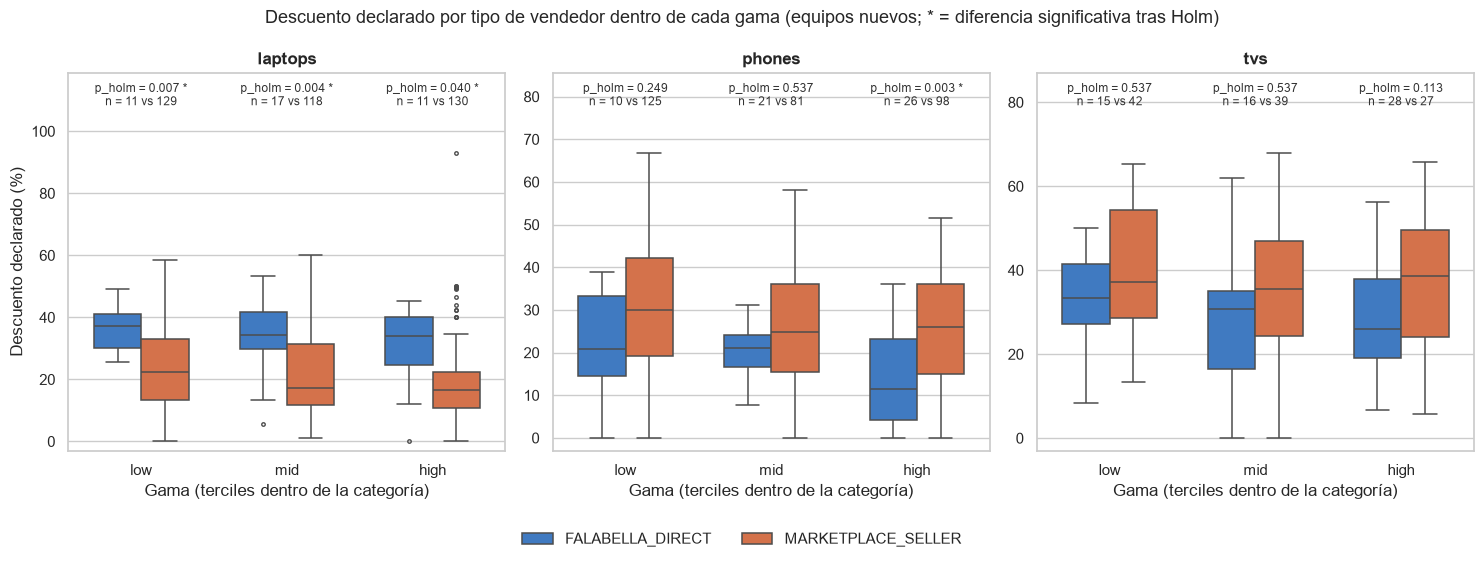

In [8]:
boxplots_por_gama(
    df_nuevos, "discount_pct", mw_descuento, "Descuento declarado (%)",
    "Descuento declarado por tipo de vendedor dentro de cada gama (equipos nuevos; * = diferencia significativa tras Holm)",
)
savefig("ana_07_descuento_vendedor_por_gama")
plt.show()

**Interpretación.**

- **En laptops, Falabella declara descuentos mucho mayores en las tres gamas**, con medianas de 37.2 %, 34.3 % y 34.0 % frente a 22.5 %, 17.1 % y 16.7 % de los sellers (p_holm = 0.007, 0.004 y 0.040; tamaños de efecto grandes, r_rb entre 0.49 y 0.60). Como el precio final no difiere (sección 1.2), el mayor descuento proviene de un **precio de lista más alto**. En la gama `mid` la mediana de `list_price` de Falabella es S/ 5,899 frente a S/ 4,799 (p_holm = 0.0004); en `low` y `high` la dirección es la misma (S/ 3,899 frente a S/ 3,463 y S/ 11,199 frente a S/ 8,499), aunque no es significativa tras la corrección.
- **En celulares de gama alta ocurre lo contrario:** Falabella declara un descuento mediano de 11.5 % frente a 25.9 % de los terceros (p_holm = 0.003, r_rb = −0.46). En el resto de celulares y en televisores, los sellers también tienen medianas de descuento mayores, pero sin significancia tras Holm (en televisores `high`, p = 0.023 sin corregir).
- **Los descuentos de 50 % o más se concentran en los televisores de terceros:** el 24.1 % de sus televisores nuevos (26 de 108) declara al menos 50 % de rebaja, frente al 8.5 % de Falabella (5 de 59). En celulares, el 7.6 % de los terceros y ningún producto de Falabella. Las laptops son la excepción: 7.7 % en Falabella (3 de 39) frente a 2.9 % en terceros.

**Lectura conjunta.** Dentro de una misma gama, ambos tipos de vendedor cobran prácticamente lo mismo, pero declaran descuentos distintos. Por lo tanto, **el porcentaje de descuento depende del precio de lista que cada vendedor declara y no de cuánto paga finalmente el comprador.** Un descuento mayor no implica un precio menor: funciona más como una herramienta de comunicación (efecto de anclaje) que como un indicador del ahorro real.

## 1.4 Robustez de los resultados

Se repiten las pruebas de precio y descuento en dos escenarios alternativos para comprobar que las conclusiones no dependen de las decisiones de la sección 0:

- **A. Base (usada arriba):** equipos nuevos, con atípicos.
- **B. Con reacondicionados:** todo el catálogo.
- **C. Sin atípicos:** equipos nuevos con `is_price_outlier == 0`.

In [9]:
escenarios = {
    "A_base_nuevos": df_nuevos,
    "B_con_reacondicionados": df,
    "C_nuevos_sin_atipicos": df_nuevos[df_nuevos["is_price_outlier"] == 0],
}
tablas = []
for nombre, data in escenarios.items():
    for variable in ["internet_price", "discount_pct"]:
        t = comparar_vendedores(data, variable)
        t.insert(0, "variable", variable)
        t.insert(0, "escenario", nombre)
        tablas.append(t)
robustez = pd.concat(tablas, ignore_index=True)
robustez.to_csv(ANA_DIR / "mannwhitney_robustez_escenarios.csv", index=False, encoding="utf-8")

resumen_robustez = (
    robustez.assign(celda=robustez["category"] + "-" + robustez["prices_category"].astype(str))
    .groupby(["escenario", "variable"])
    .apply(lambda g: pd.Series({
        "celdas_significativas_holm": int(g["significativo_holm"].sum()),
        "detalle": ", ".join(
            f"{c} ({'F>M' if r > 0 else 'F<M'})"
            for c, r in zip(g.loc[g["significativo_holm"], "celda"], g.loc[g["significativo_holm"], "r_rank_biserial"])
        ) or "ninguna",
    }), include_groups=False)
    .reset_index()
)
display(resumen_robustez)

,escenario,variable,celdas_significativas_holm,detalle
0,A_base_nuevos,discount_pct,4,"laptops-low (F>M), laptops-mid (F>M), laptops-high (F>M), phones-high (F<M)"
1,A_base_nuevos,internet_price,0,ninguna
2,B_con_reacondicionados,discount_pct,4,"laptops-low (F>M), laptops-mid (F>M), laptops-high (F>M), phones-high (F<M)"
3,B_con_reacondicionados,internet_price,0,ninguna
4,C_nuevos_sin_atipicos,discount_pct,3,"laptops-low (F>M), laptops-mid (F>M), phones-high (F<M)"
5,C_nuevos_sin_atipicos,internet_price,0,ninguna


**Interpretación.**

- **Precio:** en los tres escenarios ninguna celda es significativa tras Holm. La conclusión de que no hay diferencias de precio dentro de cada gama **no depende** de excluir los reacondicionados ni de mantener los atípicos.
- **Descuento:** el patrón se mantiene. Falabella declara más descuento en laptops `low` y `mid`, y menos en celulares `high`, en los tres escenarios. El único cambio está en laptops `high`, que deja de ser significativa al retirar los atípicos (p_holm = 0.092): sin ellos, Falabella queda con 10 productos en esa celda y la prueba pierde potencia, aunque la diferencia de medianas sigue siendo grande (35.5 % frente a 16.7 %).

## 1.5 Síntesis del Objetivo 2

1. **Para equipos nuevos, los vendedores externos no son una alternativa sistemáticamente más económica.** Dentro de la misma categoría y gama, los precios de Falabella y de los sellers no difieren significativamente en ninguna de las 9 comparaciones, y el resultado se mantiene en los tres escenarios de robustez. La aparente diferencia a nivel de categoría se explica por la mezcla de gamas: Falabella publica más productos de gama alta.
2. **La agresividad de las ofertas sí difiere, pero en sentido opuesto según la categoría.** En laptops, Falabella declara descuentos significativamente mayores, apoyados en precios de lista más altos. En celulares de gama alta son los terceros quienes declaran más descuento, y en televisores los terceros concentran las rebajas de 50 % o más.
3. **Donde el marketplace sí ofrece precios más bajos es en los equipos reacondicionados** (el 100 % de los 93 del catálogo). Se trata de un producto distinto, no de un mejor precio por el mismo producto.
4. **Limitaciones.** Se comparan publicaciones y no ventas. No se pueden emparejar modelos idénticos con las columnas disponibles, por lo que la comparación es por categoría y gama. Los grupos de Falabella son pequeños (10 a 28 por celda). Los datos provienen de una sola captura de una sola tienda.